# Regla de aprendizaje de Rosenblatt

(4 puntos posibles)

El primer esfuerzo para que el perceptrón aprendiera a partir de datos fue la regla de aprendizaje presentada por Frank Rosenblatt. En este notebook aplicaremos dicha regla para observar el comportamiento sobre un conjuinto de datos sintético. Completa el código donde se te indica con "TODO".

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/pibenitezq126/redes-neuronales-practicas/blob/main/notebooks/1_03_2_regla_de_aprendizaje.ipynb)

@juan1rving

In [1]:
# Compatibilidad automática con Google Colab y ejecución local
import os
import sys

# Si se ejecuta en Google Colab, clonamos el repositorio para disponer del módulo nni
if not os.path.exists('nni') and not os.path.exists('notebooks/nni'):
    print("Detectado entorno Google Colab. Clonando repositorio para importar nni...")
    os.system('git clone https://github.com/pibenitezq126/redes-neuronales-practicas.git')
    if os.path.exists('redes-neuronales-practicas/notebooks'):
        sys.path.append('redes-neuronales-practicas/notebooks')
elif os.path.exists('notebooks/nni'):
    sys.path.append('notebooks')

import nni.functions as nf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.inspection import DecisionBoundaryDisplay
from matplotlib.colors import ListedColormap

colors = ['red', 'blue']


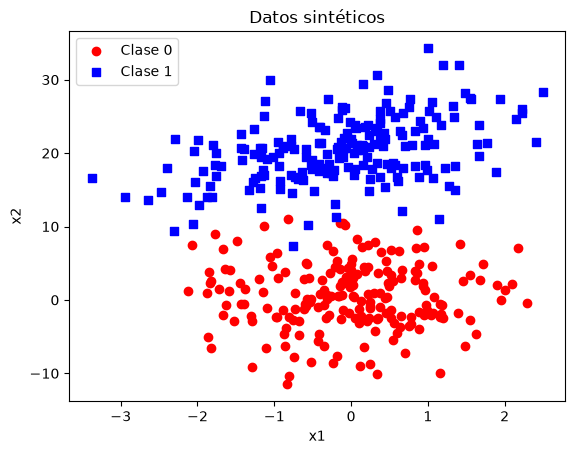

In [2]:
# Generar datos sintéticos
X, y = nf.datosSinteticos()

cmap = ListedColormap(colors[:len(np.unique(y))])

# Visualizar los datos
fig = plt.figure()
ax = fig.subplots()
ax.scatter(X.loc[y==0, 'x1'], X.loc[y==0, 'x2'], color='red', marker='o', label='Clase 0')
ax.scatter(X.loc[y==1, 'x1'], X.loc[y==1, 'x2'], color='blue', marker='s', label='Clase 1')
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_title('Datos sintéticos')
ax.legend(loc='upper left')
plt.show()

## Perceptrón

A diferencia del ejercicio previo. En esta ocasión implementaremos el perceptrón como una clase.

In [3]:
class Perceptron:
    def __init__(self, n_entradas, f_activacion):
        self.W = np.zeros((n_entradas,))
        self.b = 0.0
        self._f_activacion = f_activacion

    def inferencia(self, X):
        h = np.dot(X, self.W) + self.b
        return self._f_activacion(h)
    
def escalon(x):
    return np.where(x >= 0, 1, 0)

## Inicialización

El primer paso consite en inicializar los pesos. 

Para inicializar los pesos con una distribución normal, podemos utilizar la función `numpy.random.normal`. Esta función permite especificar la media (`loc`), la desviación estándar (`scale`) y el número de valores a generar (`size`). Por ejemplo, `np.random.normal(loc=0, scale=1, size=(2,))` genera dos valores aleatorios con media 0 y desviación estándar 1. Esta inicialización es útil para romper la simetría y facilitar el aprendizaje del perceptrón.

In [4]:
# Crear una instancia del perceptrón
clasificador = Perceptron(n_entradas=2, f_activacion=escalon)
print("Pesos iniciales:", clasificador.W)
print("Bias inicial:", clasificador.b)

Pesos iniciales: [0. 0.]
Bias inicial: 0.0


In [5]:
# TODO: Inicialización de parámetros (1 punto)
# Fijamos semilla para reproducibilidad
np.random.seed(42)
clasificador.W = np.random.normal(loc=0.0, scale=1.0, size=(2,))
clasificador.b = float(np.random.normal(loc=0.0, scale=1.0))

print("Pesos después de la inicialización:", clasificador.W)
print("Bias después de la inicialización:", clasificador.b)


Pesos después de la inicialización: [ 0.49671415 -0.1382643 ]
Bias después de la inicialización: 0.6476885381006925


### Función de pérdida

La función de pérdida nos indica que tanto nos estamos equivocando en el conjunto de datos completo.

En este notebook usaremos la suma de los errores absolutos
$$
\mathcal{L} = SAE = \sum_\mu | y^\mu - \hat{y}^\mu 
$$


In [6]:
# TODO: implementa la función de pérdida (1 punto)
def perdidaSAE(y_true, y_pred):
    # Suma de errores absolutos: SAE = sum |y - y_hat|
    return np.sum(np.abs(y_true - y_pred))

y_pred = clasificador.inferencia(X)
print("Pérdida inicial (SAE):", perdidaSAE(y, y_pred))


Pérdida inicial (SAE): 354


A continuación visualizaremos el rendimiento del clasificador de forma gráfica

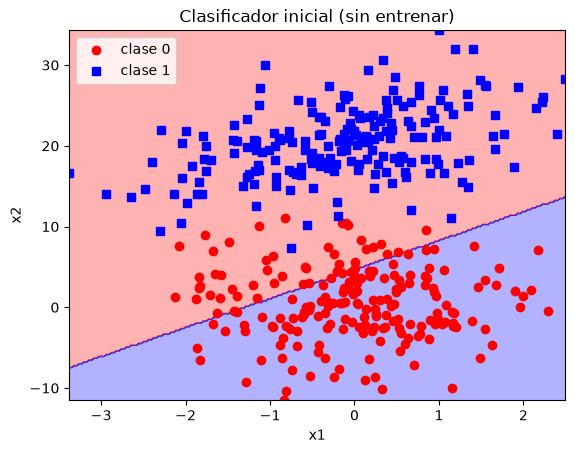

In [7]:
x1, x2 = np.meshgrid(
    np.linspace(X.iloc[:,0].min(), X.iloc[:,0].max(), num=200),
    np.linspace(X.iloc[:,1].min(), X.iloc[:,1].max(), num=200)
)
grid = np.vstack([x1.ravel(), x2.ravel()]).T
y_pred = np.reshape(clasificador.inferencia(grid), x1.shape)

fig = plt.figure()
ax = fig.subplots()
try:
    display = DecisionBoundaryDisplay(xx0=x1, xx1=x2, response=y_pred, n_classes=2)
except TypeError:
    display = DecisionBoundaryDisplay(xx0=x1, xx1=x2, response=y_pred)
display.plot(ax=ax, plot_method='contourf', cmap=cmap, alpha=0.3)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.scatter(X.loc[y==0, 'x1'], X.loc[y==0, 'x2'], color='red', marker='o', label='clase 0')
ax.scatter(X.loc[y==1, 'x1'], X.loc[y==1, 'x2'], color='blue', marker='s', label='clase 1')
ax.set_title('Clasificador inicial (sin entrenar)')
ax.legend(loc='upper left')
plt.show()


## Regla de aprendizaje

Primero, recordemos que la regla de aprendizase se basa en que cada error no guia hacia donde mover los pesos. Es decir usamos el error residual:

$$
e^\mu = y^\mu - \hat{y}^\mu
$$

Una vez definido el error residual observemos que la regla de aprendizaje se calcula como

$$
W^{t+1} = W^{t} + \eta (y - \hat{y}) X
$$

Y se repite el cálculo tantas veces como deseemos.


In [8]:
## Implementa la regla de aprendizaje (1 punto)
class ReglaDeAprendizaje:
    def __init__(self, tasa_aprendizaje=0.1):
        self.tasa_aprendizaje = tasa_aprendizaje

    def actualizar(self, perceptron, X, y):
        for xi, target in zip(X.values, y.values):
            output = perceptron.inferencia(xi)
            error = target - output
            # Regla de Rosenblatt:
            # W_nuevo = W_actual + eta * error * x
            # b_nuevo = b_actual + eta * error
            perceptron.W = perceptron.W + self.tasa_aprendizaje * error * xi
            perceptron.b = perceptron.b + self.tasa_aprendizaje * error


In [9]:
# Configuración del entrenamiento (ajustado a 30 épocas para convergencia según Diapositiva 20)
tasa_aprendizaje = 0.1
n_epocas = 30


Época 1: Pérdida (SAE): 354
Época 2: Pérdida (SAE): 108
Época 3: Pérdida (SAE): 94
Época 4: Pérdida (SAE): 96
Época 5: Pérdida (SAE): 93
Época 6: Pérdida (SAE): 82
Época 7: Pérdida (SAE): 80
Época 8: Pérdida (SAE): 82
Época 9: Pérdida (SAE): 56
Época 10: Pérdida (SAE): 54
Época 11: Pérdida (SAE): 75
Época 12: Pérdida (SAE): 76
Época 13: Pérdida (SAE): 66
Época 14: Pérdida (SAE): 58
Época 15: Pérdida (SAE): 75
Época 16: Pérdida (SAE): 62
Época 17: Pérdida (SAE): 47
Época 18: Pérdida (SAE): 61
Época 19: Pérdida (SAE): 55


Época 20: Pérdida (SAE): 55


Época 21: Pérdida (SAE): 54
Época 22: Pérdida (SAE): 52
Época 23: Pérdida (SAE): 54
Época 24: Pérdida (SAE): 50
Época 25: Pérdida (SAE): 53
Época 26: Pérdida (SAE): 50
Época 27: Pérdida (SAE): 53
Época 28: Pérdida (SAE): 42


Época 29: Pérdida (SAE): 57
Época 30: Pérdida (SAE): 55


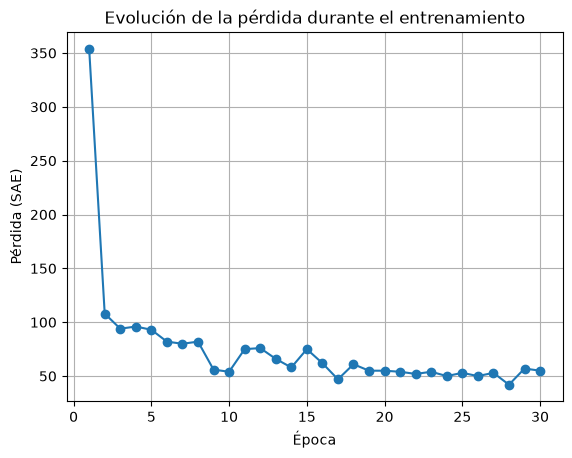

In [10]:
optimizador = ReglaDeAprendizaje(tasa_aprendizaje=tasa_aprendizaje)

historial_perdida = []

for epoca in range(n_epocas):
    y_pred = clasificador.inferencia(X)
    perdida = perdidaSAE(y, y_pred)
    print(f"Época {epoca+1}: Pérdida (SAE): {perdida}")
    historial_perdida.append(perdida)
    optimizador.actualizar(clasificador, X, y)

# Visualizar la pérdida a lo largo de las épocas
plt.plot(range(1, n_epocas + 1), historial_perdida, marker='o')
plt.xlabel('Época')
plt.ylabel('Pérdida (SAE)')
plt.title('Evolución de la pérdida durante el entrenamiento')
plt.grid()
plt.show()

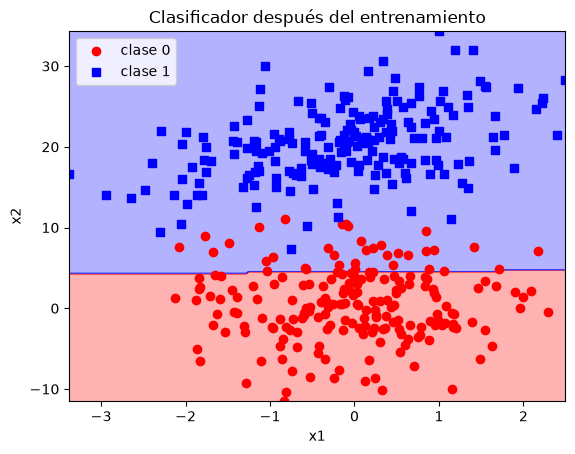

In [11]:
x1, x2 = np.meshgrid(
    np.linspace(X.iloc[:,0].min(), X.iloc[:,0].max(), num=200),
    np.linspace(X.iloc[:,1].min(), X.iloc[:,1].max(), num=200)
)
grid = np.vstack([x1.ravel(), x2.ravel()]).T
y_pred = np.reshape(clasificador.inferencia(grid), x1.shape)

fig = plt.figure()
ax = fig.subplots()
try:
    display = DecisionBoundaryDisplay(xx0=x1, xx1=x2, response=y_pred, n_classes=2)
except TypeError:
    display = DecisionBoundaryDisplay(xx0=x1, xx1=x2, response=y_pred)
display.plot(ax=ax, plot_method='contourf', cmap=cmap, alpha=0.3)
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.scatter(X.loc[y==0, 'x1'], X.loc[y==0, 'x2'], color='red', marker='o', label='clase 0')
ax.scatter(X.loc[y==1, 'x1'], X.loc[y==1, 'x2'], color='blue', marker='s', label='clase 1')
ax.set_title('Clasificador después del entrenamiento')
ax.legend(loc='upper left')
plt.show()


In [12]:
# TODO: 2 puntos, modifica los hiperparámetros hasta que tengas una clasificación adecuada.
# No tiene que ser perfecto pero si se debe observar que los puntos rojos y azules en su mayoría estén correctamente clasificados.

print("--- Evaluación Final del Clasificador Perceptrón ---")
y_pred_final = clasificador.inferencia(X)
perdida_final = perdidaSAE(y, y_pred_final)
exactitud = np.mean(y == y_pred_final) * 100

print(f"Tasa de aprendizaje (eta): {tasa_aprendizaje}")
print(f"Número de épocas: {n_epocas}")
print(f"Pesos finales aprendidos W: {clasificador.W}")
print(f"Bias final aprendido b: {clasificador.b:.4f}")
print(f"Pérdida final (SAE): {perdida_final}")
print(f"Exactitud en el conjunto de entrenamiento: {exactitud:.2f}%")
print("Conclusión: La frontera lineal separa adecuadamente los grupos de clase 0 y clase 1.")


--- Evaluación Final del Clasificador Perceptrón ---
Tasa de aprendizaje (eta): 0.1
Número de épocas: 30
Pesos finales aprendidos W: [-0.12240862  1.59179756]
Bias final aprendido b: -7.1523
Pérdida final (SAE): 36
Exactitud en el conjunto de entrenamiento: 91.00%
Conclusión: La frontera lineal separa adecuadamente los grupos de clase 0 y clase 1.
